# Étape 3 : description statistique de la base de données

Ce notebook présente la base de facteurs utilisée dans le projet : son contenu, ses statistiques descriptives, l'évolution des facteurs dans le temps, leurs corrélations, une ACP et une classification hiérarchique.

Source : bibliothèque de Kenneth French, fichiers téléchargés le 15 octobre 2026 (base CRSP d'août 2026).
- `F-F_Research_Data_5_Factors_2x3_CSV.zip` : Mkt-RF, SMB, HML, RMW, CMA et RF
- `F-F_Momentum_Factor_CSV.zip` : Mom

In [1]:
import io
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.precision", 2)
pd.set_option("display.width", 120)

## 1. Chargement

Les fichiers de Kenneth French sont des CSV avec un en-tête de texte, un bloc de données mensuelles, puis un bloc de données annuelles. On ne garde que le bloc mensuel.

In [2]:
def lire_bloc_mensuel(chemin_zip):
    # Lit le premier bloc de données (mensuel) d'un CSV de Kenneth French.
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    df.index.name = "mois"
    return df.astype(float)


ff5 = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip")
mom = lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip")

base = ff5.join(mom, how="inner")
base = base[["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom", "RF"]]
FACTEURS = ["Mkt-RF", "SMB", "HML", "RMW", "CMA", "Mom"]

print(f"FF5 : {ff5.index.min()} -> {ff5.index.max()} ({len(ff5)} mois)")
print(f"Mom : {mom.index.min()} -> {mom.index.max()} ({len(mom)} mois)")
print(f"Base fusionnée : {base.index.min()} -> {base.index.max()} ({len(base)} mois)")
base.head()

FF5 : 1963-07 -> 2026-08 (758 mois)
Mom : 1927-01 -> 2026-08 (1196 mois)
Base fusionnée : 1963-07 -> 2026-08 (758 mois)


,Mkt-RF,SMB,HML,RMW,CMA,Mom,RF
mois,,,,,,,
1963-07,-0.39,-0.48,-0.84,0.64,-1.15,1.01,0.27
1963-08,5.08,-0.80,1.72,0.40,-0.38,1.00,0.25
1963-09,-1.57,-0.43,-0.02,-0.78,0.15,0.12,0.27
1963-10,2.54,-1.34,-0.03,2.79,-2.25,3.13,0.29
1963-11,-0.86,-0.85,1.78,-0.43,2.27,-0.77,0.27


## 2. Structure de la base

- **Une ligne = un mois.** L'index est le mois (format AAAA-MM). La valeur d'une ligne est le rendement réalisé pendant ce mois.
- **Une colonne = un facteur**, exprimé en **rendement mensuel en %** (2,5 signifie +2,5 % sur le mois).
- `RF` est le taux sans risque mensuel (bon du Trésor à 1 mois). Ce n'est pas un facteur : il sert à calculer `Mkt-RF`.

Le momentum commence en 1927, les cinq facteurs en juillet 1963 : la base commune démarre donc en juillet 1963.

In [3]:
controle = pd.DataFrame({
    "type": base.dtypes.astype(str),
    "valeurs manquantes": base.isna().sum(),
    "codes -99.99 / -999": ((base == -99.99) | (base == -999)).sum(),
})
mois_attendus = pd.period_range(base.index.min(), base.index.max(), freq="M")
print("Mois manquants dans la série :", len(mois_attendus.difference(base.index)))
controle

Mois manquants dans la série : 0


,type,valeurs manquantes,codes -99.99 / -999
Mkt-RF,float64,0,0
SMB,float64,0,0
HML,float64,0,0
RMW,float64,0,0
CMA,float64,0,0
Mom,float64,0,0
RF,float64,0,0


## 3. Statistiques descriptives

Notations, pour un facteur de rendements mensuels $r_1, \dots, r_T$ (en %) :

- moyenne annualisée : $12\,\bar r$
- volatilité annualisée : $\sqrt{12}\,\hat\sigma$
- ratio de Sharpe annualisé : $\sqrt{12}\,\bar r / \hat\sigma$. Les facteurs étant des rendements excédentaires (Mkt-RF) ou des positions long-short autofinancées, on ne retranche pas de taux sans risque.
- t-stat de la moyenne : $t = \bar r / (\hat\sigma / \sqrt{T})$. Au-delà de 2 en valeur absolue, la prime moyenne est significativement non nulle au seuil de 5 %.
- asymétrie (skewness) $\mathbb{E}[(r-\mu)^3]/\sigma^3$ et kurtosis en excès $\mathbb{E}[(r-\mu)^4]/\sigma^4 - 3$ (0 pour une loi normale).
- perte maximale (max drawdown) : plus forte baisse, depuis un sommet, de la richesse cumulée $W_t = \prod_{s \le t} (1 + r_s/100)$.

In [4]:
def perte_max(r):
    w = (1 + r / 100).cumprod()
    return (w / w.cummax() - 1).min() * 100


def dates_perte_max(r):
    w = (1 + r / 100).cumprod()
    creux = (w / w.cummax() - 1).idxmin()
    return f"{w[:creux].idxmax()} à {creux}"


f = base[FACTEURS]
T = len(f)
desc = pd.DataFrame({
    "moyenne mensuelle (%)": f.mean(),
    "écart-type mensuel (%)": f.std(),
    "moyenne annualisée (%)": 12 * f.mean(),
    "volatilité annualisée (%)": np.sqrt(12) * f.std(),
    "Sharpe annualisé": np.sqrt(12) * f.mean() / f.std(),
    "t-stat moyenne": f.mean() / (f.std() / np.sqrt(T)),
    "min (%)": f.min(),
    "mois du min": f.idxmin().astype(str),
    "max (%)": f.max(),
    "mois du max": f.idxmax().astype(str),
    "médiane (%)": f.median(),
    "mois positifs (%)": (f > 0).mean() * 100,
    "asymétrie": f.skew(),
    "kurtosis en excès": f.kurt(),
    "autocorrélation ordre 1": f.apply(lambda s: s.autocorr(1)),
    "perte maximale (%)": f.apply(perte_max),
    "période de la perte maximale": f.apply(dates_perte_max),
}).T
desc

,Mkt-RF,SMB,HML,RMW,CMA,Mom
moyenne mensuelle (%),0.6,0.19,0.29,0.25,0.24,0.6
écart-type mensuel (%),4.46,3.02,2.97,2.29,2.07,4.21
moyenne annualisée (%),7.22,2.24,3.53,3.02,2.92,7.16
volatilité annualisée (%),15.44,10.46,10.29,7.92,7.18,14.57
Sharpe annualisé,0.47,0.21,0.34,0.38,0.41,0.49
t-stat moyenne,3.72,1.7,2.72,3.03,3.23,3.9
min (%),-23.19,-15.53,-13.83,-18.93,-7.06,-34.36
mois du min,1987-10,2000-03,2020-03,2000-02,2023-05,2009-04
max (%),16.1,18.54,12.86,13.04,9.0,18.05
mois du max,1974-10,2000-02,2022-01,2000-11,2001-02,2000-02


In [5]:
# Test de normalité de Jarque-Bera : H0 = les rendements suivent une loi normale
jb = pd.DataFrame({c: stats.jarque_bera(f[c])[:2] for c in FACTEURS}, index=["statistique JB", "p-valeur"]).T
jb

,statistique JB,p-valeur
Mkt-RF,123.50,1.52e-27
SMB,315.73,2.75e-69
HML,144.75,3.70e-32
RMW,3354.47,0.00e+00
CMA,63.46,1.66e-14
Mom,3013.94,0.00e+00


In [6]:
# Taux sans risque, pour situer le contexte de taux sur la période
rf = base["RF"]
print(f"RF moyen : {12 * rf.mean():.2f} % par an, max {12 * rf.max():.2f} % ({rf.idxmax()}), "
      f"min {12 * rf.min():.2f} % ({rf.idxmin()})")

RF moyen : 4.35 % par an, max 16.20 % (1981-06), min 0.00 % (2008-12)


## 4. Évolution des facteurs

Style commun aux graphiques : fond clair, une couleur fixe par facteur, grille discrète.

In [7]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
COULEURS = {
    "Mkt-RF": "#2a78d6", "SMB": "#eb6834", "HML": "#1baf7a",
    "RMW": "#eda100", "CMA": "#e87ba4", "Mom": "#008300",
}
NOMS = {
    "Mkt-RF": "Marché (Mkt-RF)", "SMB": "Taille (SMB)", "HML": "Value (HML)",
    "RMW": "Rentabilité (RMW)", "CMA": "Investissement (CMA)", "Mom": "Momentum (Mom)",
}
# Récessions américaines (NBER), pour situer les épisodes de crise
RECESSIONS = [("1969-12", "1970-11"), ("1973-11", "1975-03"), ("1980-01", "1980-07"),
              ("1981-07", "1982-11"), ("1990-07", "1991-03"), ("2001-03", "2001-11"),
              ("2007-12", "2009-06"), ("2020-02", "2020-04")]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def dates(idx):
    return idx.to_timestamp(how="end")


def bandes_recession(ax):
    for d, f_ in RECESSIONS:
        ax.axvspan(pd.Period(d, "M").to_timestamp(), pd.Period(f_, "M").to_timestamp(how="end"),
                   color="#ecebe7", lw=0, zorder=0)


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")

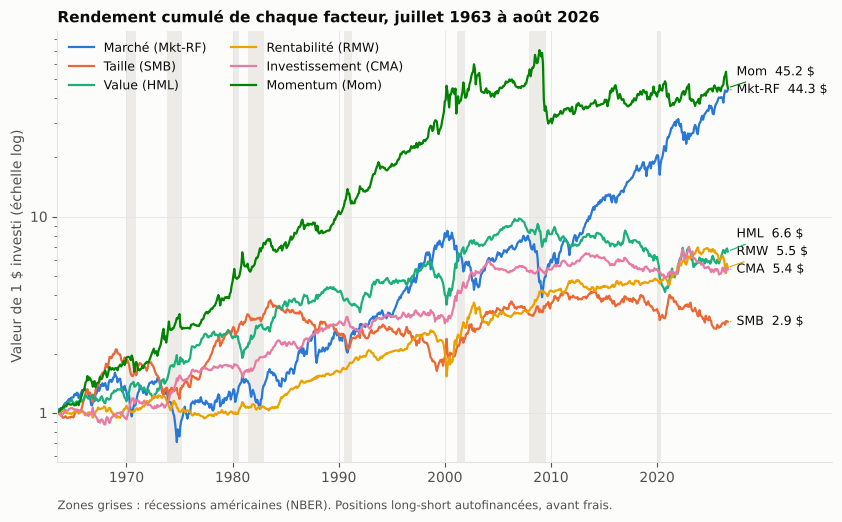

,valeur finale de 1 $
Mom,45.24
Mkt-RF,44.27
HML,6.64
RMW,5.50
CMA,5.38
SMB,2.91


In [8]:
richesse = (1 + f / 100).cumprod()
richesse.loc[base.index.min() - 1] = 1.0
richesse = richesse.sort_index()

fig, ax = plt.subplots(figsize=(10, 5.6))
bandes_recession(ax)
x = dates(richesse.index)
for c in FACTEURS:
    ax.plot(x, richesse[c], color=COULEURS[c], lw=1.6, label=NOMS[c])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_ylabel("Valeur de 1 $ investi (échelle log)")
ax.set_title("Rendement cumulé de chaque facteur, juillet 1963 à août 2026")

# étiquettes directes en fin de courbe, décalées pour éviter les chevauchements
fin = richesse.iloc[-1].sort_values()
pos = np.log10(fin.values)
for i in range(1, len(pos)):
    pos[i] = max(pos[i], pos[i - 1] + 0.09)
for (c, v), p in zip(fin.items(), pos):
    ax.annotate(f"{c}  {v:,.1f} $".replace(",", " "), xy=(x[-1], v), xytext=(x[-1] + pd.Timedelta(days=300), 10 ** p),
                color=TEXTE, fontsize=9, va="center",
                arrowprops=dict(arrowstyle="-", color=COULEURS[c], lw=0.8))
ax.set_xlim(x[0], x[-1] + pd.Timedelta(days=3600))
ax.set_xticks([pd.Timestamp(f"{a}-01-01") for a in range(1970, 2030, 10)])
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(loc="upper left", ncol=2, fontsize=9)
ax.text(0.0, -0.11, "Zones grises : récessions américaines (NBER). Positions long-short autofinancées, avant frais.",
        transform=ax.transAxes, fontsize=8.5, color=TEXTE2)
sauver(fig, "facteurs_cumules.png")
plt.show()
richesse.iloc[-1].sort_values(ascending=False).to_frame("valeur finale de 1 $")

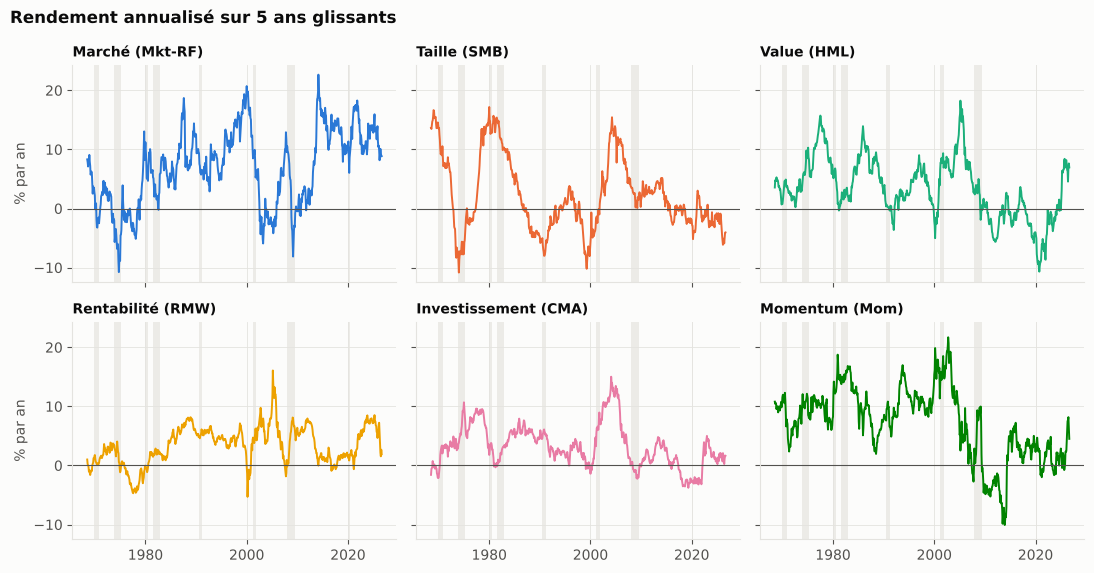

In [9]:
def petits_multiples(serie, titre, ylabel, nom, ligne_zero=True):
    fig, axes = plt.subplots(2, 3, figsize=(11, 5.8), sharex=True, sharey=True)
    for ax, c in zip(axes.flat, FACTEURS):
        bandes_recession(ax)
        s = serie[c].dropna()
        ax.plot(dates(s.index), s, color=COULEURS[c], lw=1.4)
        if ligne_zero:
            ax.axhline(0, color=TEXTE2, lw=0.8)
        ax.set_title(NOMS[c], fontsize=10)
        ax.xaxis.set_major_locator(mdates.YearLocator(20, month=1, day=1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel)
    fig.suptitle(titre, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout()
    sauver(fig, nom)
    plt.show()


rend_glissant = 12 * f.rolling(60).mean()
petits_multiples(rend_glissant, "Rendement annualisé sur 5 ans glissants", "% par an", "rendement_glissant_5ans.png")

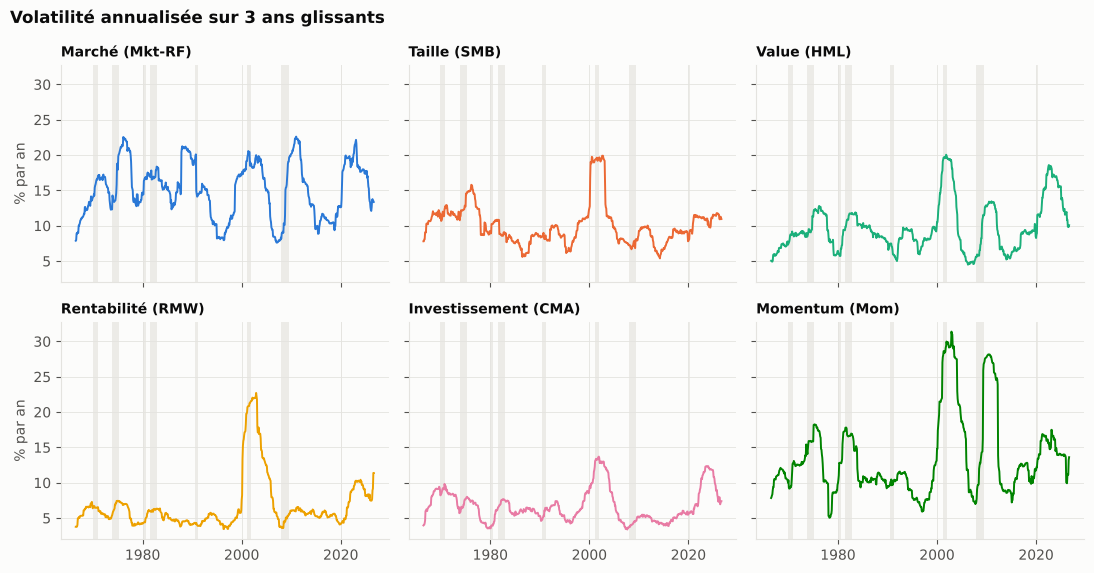

Volatilité 36 mois : min et max par facteur


,min,max,ratio max/min
Mkt-RF,7.60,22.62,2.97
SMB,5.38,19.91,3.70
HML,4.49,20.05,4.46
RMW,3.44,22.70,6.60
CMA,3.38,13.69,4.05
Mom,5.04,31.38,6.22


In [10]:
vol_glissante = np.sqrt(12) * f.rolling(36).std()
petits_multiples(vol_glissante, "Volatilité annualisée sur 3 ans glissants", "% par an", "volatilite_glissante_3ans.png",
                 ligne_zero=False)
print("Volatilité 36 mois : min et max par facteur")
pd.DataFrame({"min": vol_glissante.min(), "max": vol_glissante.max(), "ratio max/min": vol_glissante.max() / vol_glissante.min()})

In [11]:
# Performance par décennie (rendement annualisé, %)
decennie = (f.index.year // 10) * 10
par_decennie = (12 * f.groupby(decennie).mean()).round(1)
par_decennie.index = [f"{d}s" for d in par_decennie.index]
par_decennie

,Mkt-RF,SMB,HML,RMW,CMA,Mom
1960s,4.5,9.6,2.3,1.4,-1.0,10.5
1970s,1.2,4.7,7.8,-0.6,6.2,9.8
1980s,8.5,-0.4,5.9,4.9,5.6,9.0
1990s,12.8,-2.1,0.1,2.3,0.2,13.5
2000s,-1.7,7.1,7.9,8.3,6.6,1.0
2010s,13.1,-0.4,-2.3,1.4,0.2,3.2
2020s,13.1,-1.6,2.1,2.7,0.4,2.7


## 5. Matrice de corrélation

Corrélation de Pearson des rendements mensuels sur toute la période. Avec $T = 758$ mois, une corrélation est significativement non nulle au seuil de 5 % dès que $|\rho| > 1{,}96/\sqrt{T} \approx 0{,}07$.

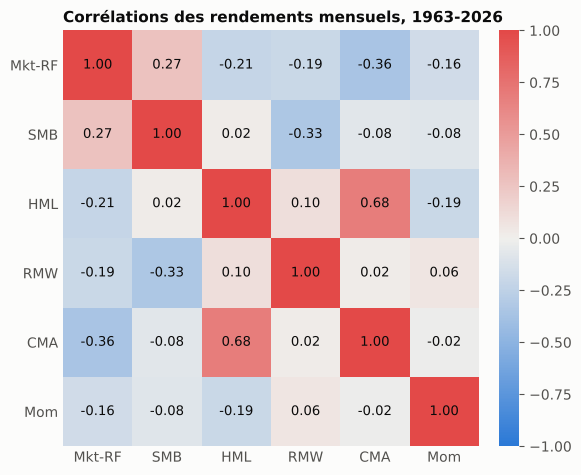

,Mkt-RF,SMB,HML,RMW,CMA,Mom
Mkt-RF,1.00,0.27,-0.21,-0.19,-0.36,-0.16
SMB,0.27,1.00,0.02,-0.33,-0.08,-0.08
HML,-0.21,0.02,1.00,0.10,0.68,-0.19
RMW,-0.19,-0.33,0.10,1.00,0.02,0.06
CMA,-0.36,-0.08,0.68,0.02,1.00,-0.02
Mom,-0.16,-0.08,-0.19,0.06,-0.02,1.00


In [12]:
corr = f.corr()

bleu, gris, rouge = "#2a78d6", "#f0efec", "#e34948"
divergente = LinearSegmentedColormap.from_list("bleu_rouge", [bleu, gris, rouge])

fig, ax = plt.subplots(figsize=(6.4, 5.4))
ax.grid(False)
im = ax.imshow(corr, cmap=divergente, vmin=-1, vmax=1)
ax.set_xticks(range(6), FACTEURS)
ax.set_yticks(range(6), FACTEURS)
ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(6):
    for j in range(6):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9.5, color=TEXTE)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cb.outline.set_visible(False)
ax.set_title("Corrélations des rendements mensuels, 1963-2026")
sauver(fig, "matrice_correlation.png")
plt.show()
corr

In [13]:
# p-valeurs des corrélations (test t de Pearson)
pval = pd.DataFrame(np.ones((6, 6)), index=FACTEURS, columns=FACTEURS)
for a in FACTEURS:
    for b in FACTEURS:
        if a != b:
            pval.loc[a, b] = stats.pearsonr(f[a], f[b])[1]
pval.map(lambda p: f"{p:.3f}")

,Mkt-RF,SMB,HML,RMW,CMA,Mom
Mkt-RF,1.000,0.000,0.000,0.000,0.000,0.000
SMB,0.000,1.000,0.650,0.000,0.036,0.030
HML,0.000,0.650,1.000,0.009,0.000,0.000
RMW,0.000,0.000,0.009,1.000,0.581,0.125
CMA,0.000,0.036,0.000,0.581,1.000,0.599
Mom,0.000,0.030,0.000,0.125,0.599,1.000


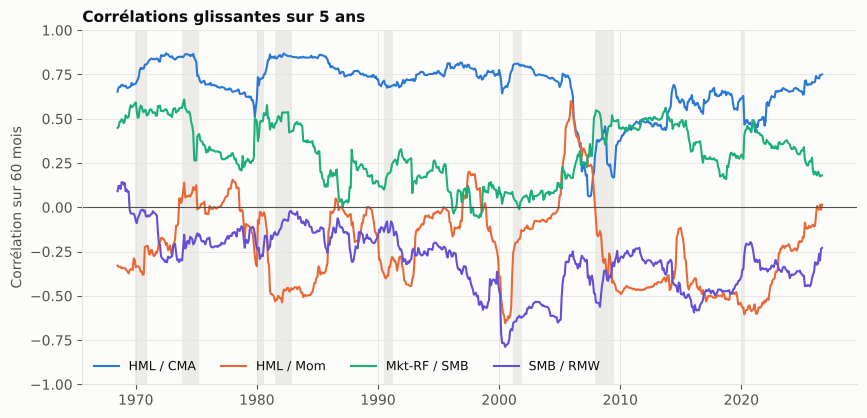

In [14]:
# Les corrélations sont-elles stables ? Corrélation glissante sur 5 ans pour les paires marquantes
paires = [("HML", "CMA"), ("HML", "Mom"), ("Mkt-RF", "SMB"), ("SMB", "RMW")]
fig, ax = plt.subplots(figsize=(10, 4.6))
bandes_recession(ax)
couleurs_paires = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6"]
for (a, b), col in zip(paires, couleurs_paires):
    rc = f[a].rolling(60).corr(f[b]).dropna()
    ax.plot(dates(rc.index), rc, color=col, lw=1.5, label=f"{a} / {b}")
ax.axhline(0, color=TEXTE2, lw=0.8)
ax.set_ylim(-1, 1)
ax.set_ylabel("Corrélation sur 60 mois")
ax.set_title("Corrélations glissantes sur 5 ans")
ax.legend(loc="lower left", ncol=4, fontsize=9)
sauver(fig, "correlations_glissantes.png")
plt.show()

## 6. Analyse en composantes principales (ACP)

On applique l'ACP aux rendements **centrés-réduits**, ce qui revient à diagonaliser la matrice de corrélation $C$ :

$$C = V \Lambda V^\top, \qquad \Lambda = \mathrm{diag}(\lambda_1 \ge \dots \ge \lambda_6), \qquad \sum_k \lambda_k = 6$$

- $\lambda_k / 6$ est la part de variance totale expliquée par la composante $k$.
- La colonne $v_k$ de $V$ donne les poids des facteurs dans la composante $k$.
- La corrélation entre le facteur $j$ et la composante $k$ vaut $v_{jk}\sqrt{\lambda_k}$ (cercle des corrélations).
- Critère de Kaiser : on retient les composantes avec $\lambda_k > 1$, c'est-à-dire qui résument plus d'information qu'un facteur seul.

Si les facteurs étaient indépendants, toutes les valeurs propres vaudraient 1 et chaque composante expliquerait 1/6 ≈ 16,7 % de la variance.

In [15]:
z = (f - f.mean()) / f.std()
valeurs_propres, vecteurs = np.linalg.eigh(corr.values)
ordre = np.argsort(valeurs_propres)[::-1]
valeurs_propres, vecteurs = valeurs_propres[ordre], vecteurs[:, ordre]
# convention de signe : la plus grande composante en valeur absolue est positive
vecteurs = vecteurs * np.sign(vecteurs[np.abs(vecteurs).argmax(axis=0), range(6)])

CP = [f"CP{k}" for k in range(1, 7)]
variance = pd.DataFrame({
    "valeur propre": valeurs_propres,
    "variance expliquée (%)": 100 * valeurs_propres / 6,
    "variance cumulée (%)": 100 * np.cumsum(valeurs_propres) / 6,
}, index=CP)
poids = pd.DataFrame(vecteurs, index=FACTEURS, columns=CP)
correlations_cp = poids * np.sqrt(valeurs_propres)
variance

,valeur propre,variance expliquée (%),variance cumulée (%)
CP1,1.95,32.56,32.56
CP2,1.45,24.24,56.80
CP3,1.01,16.83,73.63
CP4,0.71,11.84,85.47
CP5,0.60,9.98,95.45
CP6,0.27,4.55,100.00


In [16]:
poids.round(2)

,CP1,CP2,CP3,CP4,CP5,CP6
Mkt-RF,-0.47,0.27,-0.28,0.37,0.69,0.12
SMB,-0.26,0.54,0.30,0.50,-0.55,0.10
HML,0.55,0.39,-0.08,0.23,0.18,-0.67
RMW,0.25,-0.47,-0.47,0.66,-0.21,0.16
CMA,0.59,0.28,0.18,0.01,0.24,0.69
Mom,-0.01,-0.43,0.76,0.37,0.30,-0.13


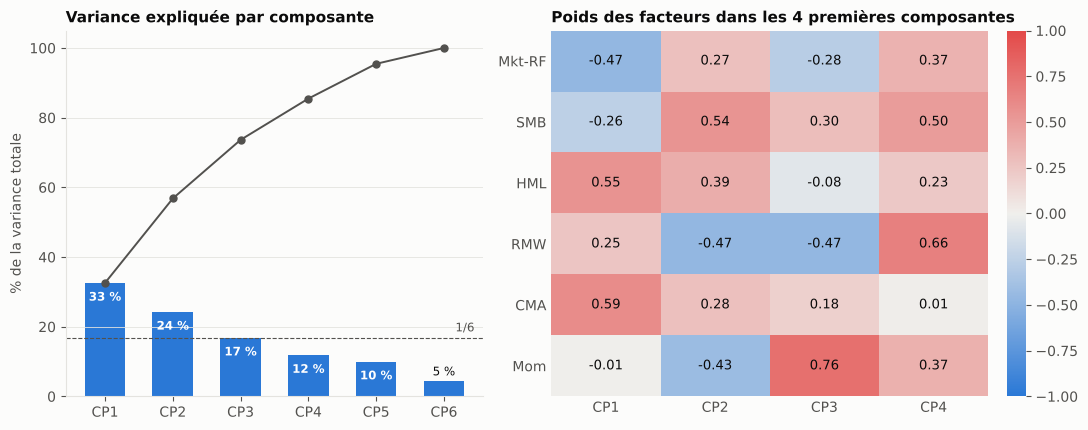

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.4), gridspec_kw={"width_ratios": [1, 1.15]})

ax1.bar(CP, variance["variance expliquée (%)"], color="#2a78d6", width=0.6)
ax1.plot(CP, variance["variance cumulée (%)"], color=TEXTE2, lw=1.4, marker="o", ms=5)
ax1.axhline(100 / 6, color=TEXTE2, lw=0.8, ls="--")
ax1.text(5.45, 100 / 6 + 2, "1/6", color=TEXTE2, fontsize=8.5, ha="right")
for i, v in enumerate(variance["variance expliquée (%)"]):
    if v > 8:
        ax1.text(i, v - 2.5, f"{v:.0f} %", ha="center", va="top", fontsize=8.5, color="white", fontweight="bold")
    else:
        ax1.text(i, v + 1.5, f"{v:.0f} %", ha="center", fontsize=8.5, color=TEXTE)
ax1.set_ylim(0, 105)
ax1.set_ylabel("% de la variance totale")
ax1.set_title("Variance expliquée par composante")
ax1.grid(axis="x", visible=False)

ax2.grid(False)
im = ax2.imshow(poids.iloc[:, :4], cmap=divergente, vmin=-1, vmax=1, aspect="auto")
ax2.set_xticks(range(4), CP[:4])
ax2.set_yticks(range(6), FACTEURS)
ax2.tick_params(length=0)
for s in ax2.spines.values():
    s.set_visible(False)
for i in range(6):
    for j in range(4):
        ax2.text(j, i, f"{poids.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9.5, color=TEXTE)
cb = fig.colorbar(im, ax=ax2, fraction=0.05, pad=0.04)
cb.outline.set_visible(False)
ax2.set_title("Poids des facteurs dans les 4 premières composantes")
fig.tight_layout()
sauver(fig, "acp_variance_poids.png")
plt.show()

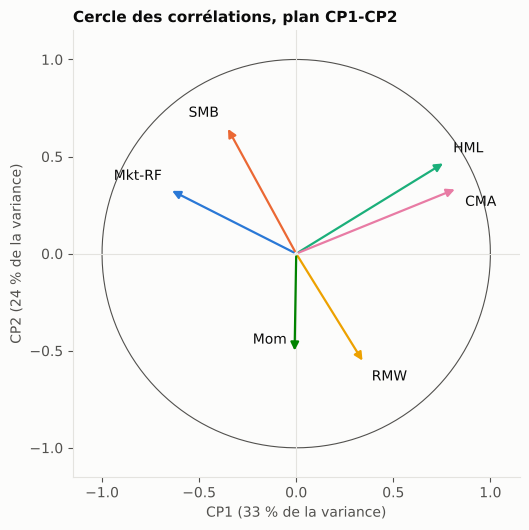

,CP1,CP2,CP3
Mkt-RF,-0.65,0.33,-0.28
SMB,-0.36,0.65,0.30
HML,0.77,0.47,-0.08
RMW,0.35,-0.56,-0.47
CMA,0.83,0.34,0.18
Mom,-0.01,-0.51,0.76


In [18]:
fig, ax = plt.subplots(figsize=(5.8, 5.8))
ax.grid(False)
t = np.linspace(0, 2 * np.pi, 300)
ax.plot(np.cos(t), np.sin(t), color=TEXTE2, lw=0.8)
ax.axhline(0, color=GRILLE, lw=0.8)
ax.axvline(0, color=GRILLE, lw=0.8)
decalage = {"Mkt-RF": (0.04, 0.05), "SMB": (0.04, 0.05), "HML": (0.04, 0.05),
            "RMW": (0.04, -0.09), "CMA": (0.04, -0.09), "Mom": (0.04, 0.05)}
for c in FACTEURS:
    x_, y_ = correlations_cp.loc[c, "CP1"], correlations_cp.loc[c, "CP2"]
    ax.annotate("", xy=(x_, y_), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color=COULEURS[c], lw=1.6, mutation_scale=12))
    dx, dy = decalage[c]
    ax.text(x_ + dx * np.sign(x_ or 1), y_ + dy, c, color=TEXTE, fontsize=10, ha="left" if x_ >= 0 else "right")
ax.set_xlim(-1.15, 1.15)
ax.set_ylim(-1.15, 1.15)
ax.set_aspect("equal")
ax.set_xlabel(f"CP1 ({variance.iloc[0, 1]:.0f} % de la variance)")
ax.set_ylabel(f"CP2 ({variance.iloc[1, 1]:.0f} % de la variance)")
ax.set_title("Cercle des corrélations, plan CP1-CP2")
sauver(fig, "acp_cercle_correlations.png")
plt.show()
correlations_cp.iloc[:, :3].round(2)

## 7. Classification hiérarchique (dendrogramme)

On regroupe les facteurs qui évoluent ensemble. La distance entre deux facteurs est construite à partir de leur corrélation :

$$d_{ij} = \sqrt{2\,(1 - \rho_{ij})}$$

C'est la distance euclidienne entre les deux séries centrées-réduites (à un facteur $\sqrt{T}$ près) : elle vaut 0 si $\rho = 1$, $\sqrt 2 \approx 1{,}41$ si les facteurs sont non corrélés, et 2 si $\rho = -1$.

Agrégation par la méthode de Ward, qui fusionne à chaque étape les deux groupes dont la réunion augmente le moins la variance intra-groupe.

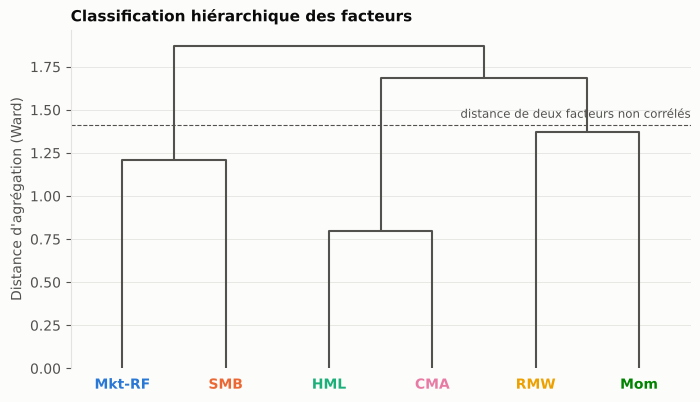

,groupe a,groupe b,distance,taille
0,2.0,4.0,0.80,2.0
1,0.0,1.0,1.21,2.0
2,3.0,5.0,1.37,2.0
3,6.0,8.0,1.68,4.0
4,7.0,9.0,1.87,6.0


In [19]:
distance = np.sqrt(2 * (1 - corr.values))
np.fill_diagonal(distance, 0)
Z = linkage(squareform(distance, checks=False), method="ward")

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.grid(axis="x", visible=False)
dendrogram(Z, labels=FACTEURS, ax=ax, color_threshold=0, above_threshold_color=TEXTE2,
           leaf_font_size=10)
for lbl in ax.get_xticklabels():
    lbl.set_color(COULEURS[lbl.get_text()])
    lbl.set_fontweight("bold")
ax.axhline(np.sqrt(2), color=TEXTE2, lw=0.8, ls="--")
ax.text(ax.get_xlim()[1], np.sqrt(2) + 0.04, "distance de deux facteurs non corrélés", color=TEXTE2,
        fontsize=8.5, ha="right")
ax.set_ylabel("Distance d'agrégation (Ward)")
ax.set_title("Classification hiérarchique des facteurs")
ax.spines["bottom"].set_visible(False)
sauver(fig, "dendrogramme.png")
plt.show()

pd.DataFrame(Z, columns=["groupe a", "groupe b", "distance", "taille"]).round(3)

In [20]:
pd.DataFrame(distance, index=FACTEURS, columns=FACTEURS).round(2)

,Mkt-RF,SMB,HML,RMW,CMA,Mom
Mkt-RF,0.00,1.21,1.56,1.54,1.65,1.53
SMB,1.21,0.00,1.40,1.63,1.47,1.47
HML,1.56,1.40,0.00,1.35,0.80,1.54
RMW,1.54,1.63,1.35,0.00,1.40,1.37
CMA,1.65,1.47,0.80,1.40,0.00,1.43
Mom,1.53,1.47,1.54,1.37,1.43,0.00
